# T14: bit-reproducible scorecards

Every figure below is regenerated from the small tables in `data/`, which `make_data.py` writes
(the `alignment` table per env, then `runs` from the `runs/t14_*` scorecard directories).
Colours: **OpenBLAS (new `ss_openblas`) = blue**, **Accelerate (old `ss_local`) = orange**.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
DATA, FIG = Path("data"), Path("figures"); FIG.mkdir(exist_ok=True)
C = {"openblas": "#2a78d6", "accelerate": "#eb6834"}
NAME = {"openblas": "OpenBLAS (ss_openblas)", "accelerate": "Accelerate (ss_local)"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "0.9", "grid.linewidth": 0.6, "axes.axisbelow": True})

## 1. The root cause: `ddot` depends on memory alignment under Accelerate

For each primitive and vector/matrix size, the fraction of random inputs whose result changes
when the *identical* data is copied to a buffer at a different 8-byte offset within a 64-byte line.
Any value above 0 means the result depends on where numpy happened to put the array.

backend                         accelerate                     openblas       \
n                                     8      25    100    1000     8    25     
primitive                                                                      
J.T @ f  [BLAS gemv]                   0.0  0.000  0.00  0.000      0.0  0.0   
np.dot(v, v)  [BLAS ddot]              0.0  0.575  0.60  0.525      0.0  0.0   
np.linalg.norm(v)                      0.0  0.275  0.15  0.300      0.0  0.0   
np.sum(v * v)  [numpy, no BLAS]        0.0  0.000  0.00  0.000      0.0  0.0   
scipy.linalg.svd(J)                    0.0  0.000  0.00  0.000      0.0  0.0   

backend                                    
n                               100  1000  
primitive                                  
J.T @ f  [BLAS gemv]             0.0  0.0  
np.dot(v, v)  [BLAS ddot]        0.0  0.0  
np.linalg.norm(v)                0.0  0.0  
np.sum(v * v)  [numpy, no BLAS]  0.0  0.0  
scipy.linalg.svd(J)              0.0  0.0

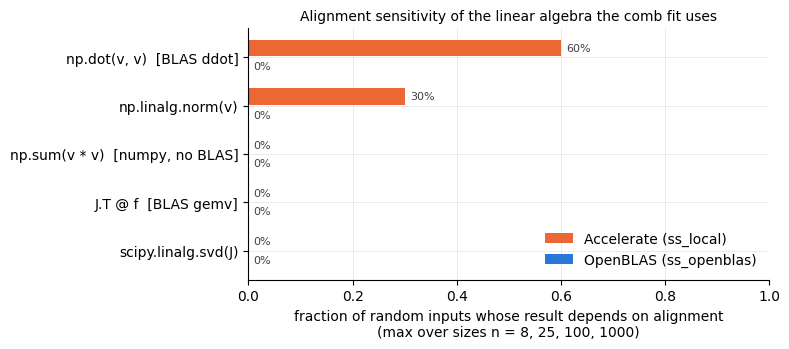

In [2]:
al = pd.concat([pd.read_csv(f) for f in sorted(DATA.glob("alignment_*.csv"))])
display(al.pivot_table(index="primitive", columns=["backend", "n"], values="frac_sensitive"))
prims = list(dict.fromkeys(al.primitive))
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(prims)); h = 0.38
for k, (b, off) in enumerate([("accelerate", -h/2), ("openblas", h/2)]):
    v = al[al.backend == b].groupby("primitive").frac_sensitive.max().reindex(prims)
    ax.barh(y + off, v.values, height=h - 0.04, color=C[b], label=NAME[b])
    for yi, vi in zip(y + off, v.values):
        ax.text(vi + 0.01, yi, f"{vi:.0%}", va="center", fontsize=8, color="0.25")
ax.set_yticks(y, prims); ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.set_xlabel("fraction of random inputs whose result depends on alignment\n(max over sizes n = 8, 25, 100, 1000)")
ax.legend(frameon=False, loc="lower right"); ax.set_title("Alignment sensitivity of the linear algebra the comb fit uses", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "fig_alignment_sensitivity.png", dpi=140); plt.show()

Only BLAS level-1 `ddot` (and `np.linalg.norm`, which calls it) is affected, and only under Accelerate.
scipy's `least_squares` (trf) takes norms of the step and gradient on every iteration to set its trust-region radius,
so a last-bit difference changes the iteration path and the point where it stops.

## 2. Run-to-run final-period differences, before vs after

Each point is one star in one pair of 200-star scorecard runs (`synthetic:n=200,seed=0`) on the same
backend, at different worker counts (4/8/10) plus one same-config repeat. Identical periods
(relative difference exactly 0) are drawn on the "identical" line at the bottom.

n_stars  n_differ  \
backend    pair                                                     
accelerate before_w10 vs before_w10_pass2           200        20   
           before_w10 vs before_w4_pass2            200        16   
           before_w10 vs before_w8_pass2            200        17   
           before_w4 vs before_w10                  200        19   
           before_w4 vs before_w10_pass2            200        19   
           before_w4 vs before_w4_pass2             200        16   
           before_w4 vs before_w8                   200        19   
           before_w4 vs before_w8_pass2             200        17   
           before_w4_pass2 vs before_w10_pass2      200        20   
           before_w4_pass2 vs before_w8_pass2       200        16   
           before_w8 vs before_w10                  200        19   
           before_w8 vs before_w10_pass2            200        18   
           before_w8 vs before_w4_pass2             200        19   
           before_w8 vs before_w8_pass2             200        19   
           before_w8_pass2 vs before_w10_pass2      200        20   
openblas   after_w10 vs after_w10_pass2             200         0   
           after_w10 vs after_w4_pass2              200         0   
           after_w10 vs after_w4_repeat             200         0   
           after_w10 vs after_w8_pass2              200         0   
           after_w10_pass2 vs after_w4_repeat       200         0   
           after_w4 vs after_w10                    200         0   
           after_w4 vs after_w10_pass2              200         0   
           after_w4 vs after_w4_pass2               200         0   
           after_w4 vs after_w4_repeat              200         0   
           after_w4 vs after_w8                     200         0   
           after_w4 vs after_w8_pass2               200         0   
           after_w4_pass2 vs after_w10_pass2        200         0   
           after_w4_pass2 vs after_w4_repeat        200         0   
           after_w4_pass2 vs after_w8_pass2         200         0   
           after_w8 vs after_w10                    200         0   
           after_w8 vs after_w10_pass2              200         0   
           after_w8 vs after_w4_pass2               200         0   
           after_w8 vs after_w4_repeat              200         0   
           after_w8 vs after_w8_pass2               200         0   
           after_w8_pass2 vs after_w10_pass2        200         0   
           after_w8_pass2 vs after_w4_repeat        200         0   

                                                max_rel_diff  \
backend    pair                                                
accelerate before_w10 vs before_w10_pass2       1.989368e-07   
           before_w10 vs before_w4_pass2        1.070583e-03   
           before_w10 vs before_w8_pass2        8.384066e-04   
           before_w4 vs before_w10              3.318525e-05   
           before_w4 vs before_w10_pass2        3.318525e-05   
           before_w4 vs before_w4_pass2         1.037363e-03   
           before_w4 vs before_w8               3.318525e-05   
           before_w4 vs before_w8_pass2         8.051936e-04   
           before_w4_pass2 vs before_w10_pass2  1.069439e-03   
           before_w4_pass2 vs before_w8_pass2   2.319286e-04   
           before_w8 vs before_w10              5.598853e-07   
           before_w8 vs before_w10_pass2        4.528975e-07   
           before_w8 vs before_w4_pass2         1.070583e-03   
           before_w8 vs before_w8_pass2         8.384066e-04   
           before_w8_pass2 vs before_w10_pass2  8.377043e-04   
openblas   after_w10 vs after_w10_pass2         0.000000e+00   
           after_w10 vs after_w4_pass2          0.000000e+00   
           after_w10 vs after_w4_repeat         0.000000e+00   
           after_w10 vs after_w8_pass2          0.000000e+00   
           after_w10_pass2 vs after_w4_repeat   0.000000e+00   
           after_

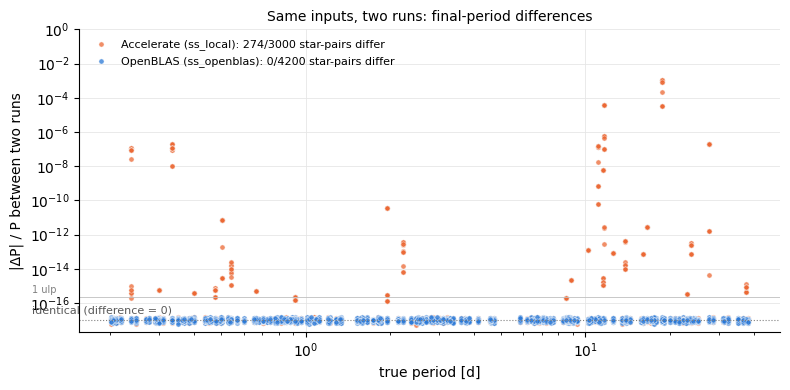

In [3]:
rp = pd.read_csv(DATA / "run_pairs.csv")
summ = (rp.assign(differs=rp.rel_diff > 0, outcome_changed=rp.outcome_a != rp.outcome_b)
          .groupby(["backend", "pair"]).agg(n_stars=("star_id", "size"), n_differ=("differs", "sum"),
                                             max_rel_diff=("rel_diff", "max"), n_outcome_changed=("outcome_changed", "sum")))
display(summ)
FLOOR = 1e-17
fig, ax = plt.subplots(figsize=(8, 4))
rng = np.random.default_rng(0)
for b in ["accelerate", "openblas"]:
    s = rp[rp.backend == b]
    yv = np.where(s.rel_diff > 0, s.rel_diff, FLOOR) * np.exp(rng.normal(0, 0.15, len(s)) * (s.rel_diff == 0))
    nd, n = int((s.rel_diff > 0).sum()), len(s)
    ax.scatter(s.true_period, yv, s=14, color=C[b], alpha=0.75, edgecolor="white", linewidth=0.4,
               label=f"{NAME[b]}: {nd}/{n} star-pairs differ")
ax.axhline(FLOOR, color="0.5", lw=0.8, ls=":"); ax.text(0.105, FLOOR * 2.5, "identical (difference = 0)", fontsize=8, color="0.35")
ax.axhline(2.2e-16, color="0.75", lw=0.6); ax.text(0.105, 4e-16, "1 ulp", fontsize=7, color="0.5")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(FLOOR / 5, 1)
ax.set_xlabel("true period [d]"); ax.set_ylabel("|ΔP| / P between two runs")
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Same inputs, two runs: final-period differences", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "fig_run_to_run_diffs.png", dpi=140); plt.show()

## 3. Runtime: 200-star synthetic scorecard by worker count and backend

`wall_seconds` from each run's `metrics.json`: the time spent in the worker pool, which excludes suite
generation and figure-making. Measured on Rae's current workstation, an Intel i5-1038NG7 with 4 physical
cores / 8 threads, with no other session's benchmark running (each run waited for one to finish;
`runs/t14_timing.log`). Two passes were run in opposite orders (pass 1: OpenBLAS then Accelerate, 4→10 workers;
pass 2: Accelerate then OpenBLAS, 10→4) to counterbalance run-order/thermal effects on a laptop CPU.
`after_w4_repeat` is excluded from timing: another session's scorecard overlapped it.

,run,backend,n_workers,wall_seconds,median_star_seconds,p90_star_seconds,git_commit,timing_pass,timing_clean
0,before_w4,accelerate,4,166.659565,3.222441,4.534658,faddcab-dirty,1,True
1,before_w8,accelerate,8,161.929125,6.227792,8.575654,faddcab-dirty,1,True
2,before_w10,accelerate,10,170.178002,7.826787,11.020637,faddcab-dirty,1,True
3,before_w4_pass2,accelerate,4,162.132699,2.954407,4.373541,faddcab-dirty,2,True
4,before_w8_pass2,accelerate,8,157.810932,5.763092,8.397600,faddcab-dirty,2,True
5,before_w10_pass2,accelerate,10,119.934834,5.328949,8.169160,faddcab-dirty,2,True
6,after_w4,openblas,4,192.523503,3.486212,5.549687,faddcab-dirty,1,True
7,after_w8,openblas,8,179.503503,6.450643,9.438877,faddcab-dirty,1,True
8,after_w10,openblas,10,179.151183,8.154105,11.725900,faddcab-dirty,1,True
9,after_w4_pass2,openblas,4,126.202580,2.330601,3.290653,faddcab-dirty,2,True


mean_wall_s  min_wall_s  max_wall_s  mean_median_star_s
backend    n_workers                                                         
accelerate 4                164.4       162.1       166.7                 3.1
           8                159.9       157.8       161.9                 6.0
           10               145.1       119.9       170.2                 6.6
openblas   4                159.4       126.2       192.5                 2.9
           8                157.2       134.9       179.5                 5.7
           10               158.1       137.0       179.2                 7.3

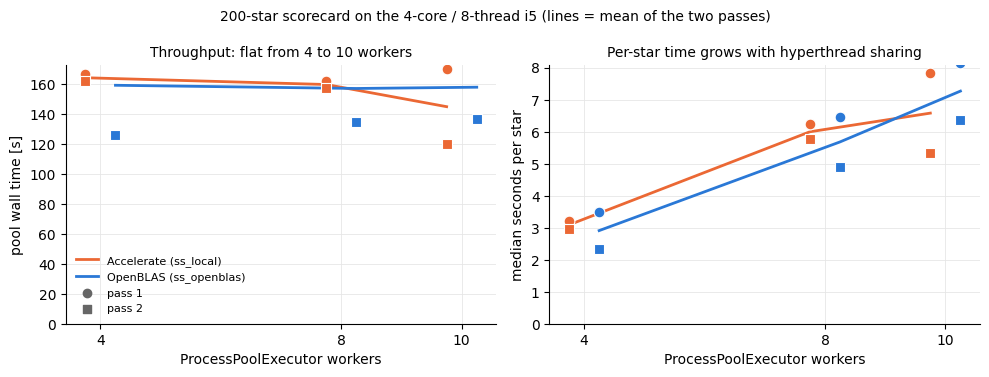

In [4]:
tm = pd.read_csv(DATA / "timing.csv")
display(tm)
clean = tm[tm.timing_clean]
display(clean.groupby(["backend", "n_workers"]).agg(mean_wall_s=("wall_seconds", "mean"), min_wall_s=("wall_seconds", "min"),
        max_wall_s=("wall_seconds", "max"), mean_median_star_s=("median_star_seconds", "mean")).round(1))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
off = {"accelerate": -0.25, "openblas": 0.25}
for b in ["accelerate", "openblas"]:
    s = clean[clean.backend == b]
    for ax, col, lab in [(axes[0], "wall_seconds", "pool wall time [s]"), (axes[1], "median_star_seconds", "median seconds per star")]:
        for pas, mk in [(1, "o"), (2, "s")]:
            q = s[s.timing_pass == pas]
            ax.scatter(q.n_workers + off[b], q[col], color=C[b], marker=mk, s=60, edgecolor="white", linewidth=0.8, zorder=3)
        m = s.groupby("n_workers")[col].mean()
        ax.plot(m.index + off[b], m.values, color=C[b], lw=2, label=NAME[b], zorder=2)
        ax.set_xticks([4, 8, 10]); ax.set_xlabel("ProcessPoolExecutor workers"); ax.set_ylabel(lab); ax.set_ylim(0, None)
axes[0].scatter([], [], color="0.4", marker="o", label="pass 1"); axes[0].scatter([], [], color="0.4", marker="s", label="pass 2")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
axes[0].set_title("Throughput: flat from 4 to 10 workers", fontsize=10)
axes[1].set_title("Per-star time grows with hyperthread sharing", fontsize=10)
fig.suptitle("200-star scorecard on the 4-core / 8-thread i5 (lines = mean of the two passes)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "fig_runtime_vs_workers.png", dpi=140); plt.show()

## 4. One-time shift from switching backend

OpenBLAS and Accelerate round differently, so moving to `ss_openblas` shifts final periods once (relative to the
committed baseline run `runs/t4_after`), at the 1e-5 level, with no outcome changes. After that, OpenBLAS runs agree exactly with each other.

In [5]:
import json
a = pd.read_csv("../../runs/t4_after/per_star.csv").set_index("star_id")
b = pd.read_csv("../../runs/t14_after_w4/per_star.csv").set_index("star_id").loc[a.index]
rel = ((a.final_period - b.final_period).abs() / a.final_period)
print(f"stars with any final-period change: {(rel > 0).sum()} / {len(a)};  max relative change {rel.max():.2g};  "
      f"median among changed {rel[rel > 0].median():.2g};  outcome changes: {(a.final_outcome != b.final_outcome).sum()}")
wa = pd.read_csv("../../runs/t4_after/per_method.csv").query("method == 'wavelet'").set_index("star_id").top1
wb = pd.read_csv("../../runs/t14_after_w4/per_method.csv").query("method == 'wavelet'").set_index("star_id").top1.loc[wa.index]
wr = ((wa - wb).abs() / wa).dropna()
print(f"wavelet top-1 changes: {(wr > 0).sum()} stars, max relative {wr.max():.2g}")

stars with any final-period change: 128 / 200;  max relative change 9e-05;  median among changed 1.5e-14;  outcome changes: 0
wavelet top-1 changes: 178 stars, max relative 8.2e-09
